**Additional example: failure time of an adhesive** (Victor Z and J E Umaña, UW-Madison, 2024).
The time to failure is $X\sim\mathrm{Exp}(\beta)$ with average $\mathbb{E}_X=\beta=36$ months.
The probability that the material survives 12 months is the survival function
$\mathbb{P}(X>12)=1-F(12)=e^{-12/\beta}$.
Python names: `beta`, realizations `x_omega`, pdf/cdf from `scipy.stats.expon(scale=beta)`.

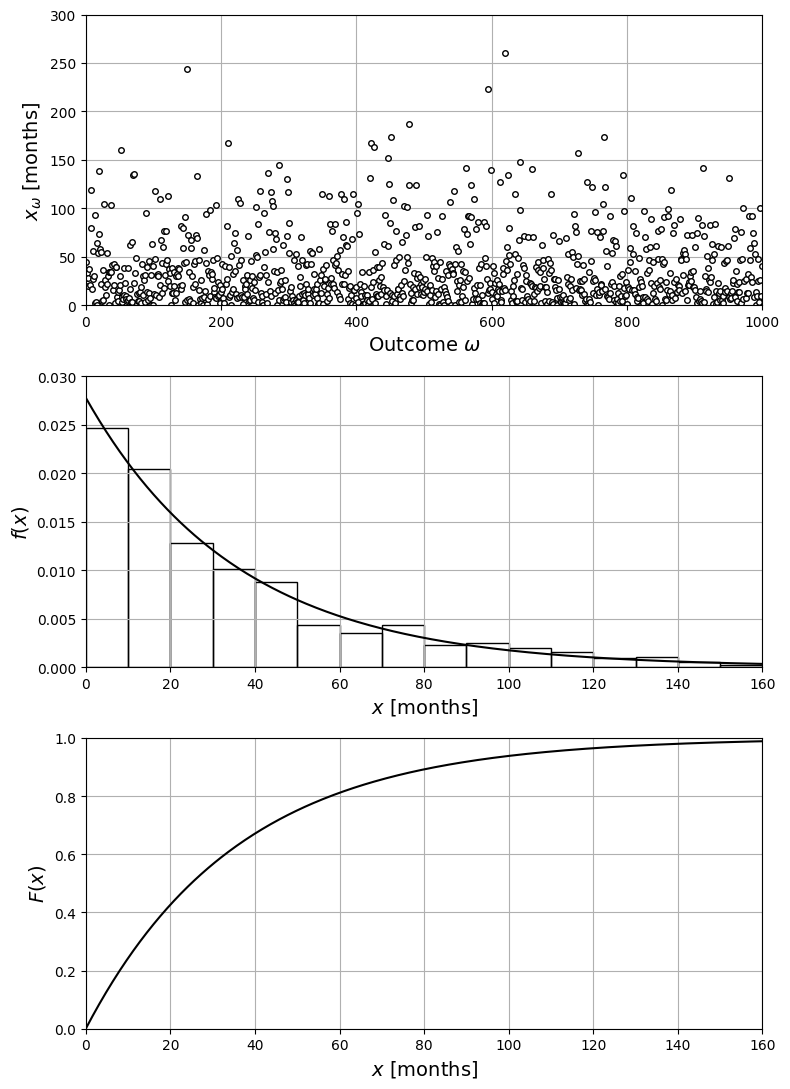

P(X > 12) = 1 - F(12) = 0.7165  (e^(-12/beta) = 0.7165)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon

beta = 3 * 12            # months (scale; intensity eta = 1/beta)
X = expon(scale=beta)

np.random.seed(0)
S = 1000
x_omega = X.rvs(size=S)

x = np.linspace(0, 160, 400)
fig, axs = plt.subplots(3, 1, figsize=(8, 11))
axs[0].plot(x_omega, 'ko', markerfacecolor='w', markersize=4)
axs[0].set_xlabel(r'Outcome $\omega$', fontsize=14)
axs[0].set_ylabel(r'$x_\omega$ [months]', fontsize=14)
axs[0].axis([0, S, 0, 300])
axs[1].hist(x_omega, bins=np.arange(0, 161, 10), density=True, edgecolor='black', facecolor='none')
axs[1].plot(x, X.pdf(x), 'k', linewidth=1.5)
axs[1].set_xlabel('$x$ [months]', fontsize=14)
axs[1].set_ylabel('$f(x)$', fontsize=14)
axs[1].axis([0, 160, 0, 0.03])
axs[2].plot(x, X.cdf(x), 'k', linewidth=1.5)
axs[2].set_xlabel('$x$ [months]', fontsize=14)
axs[2].set_ylabel('$F(x)$', fontsize=14)
axs[2].axis([0, 160, 0, 1])
for ax in axs:
    ax.grid(True)
plt.tight_layout()
plt.show()

print(f"P(X > 12) = 1 - F(12) = {X.sf(12):.4f}  (e^(-12/beta) = {np.exp(-12/beta):.4f})")